In [1]:
from pathlib import Path
import os
# The project folder is the folder that contains data/, notebooks/, results/ ...
PROJECT_DIR = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
PROJECT_DIR = Path(os.environ.get('PROJECT_DIR', PROJECT_DIR))
print('Project folder:', PROJECT_DIR)
assert (PROJECT_DIR / 'data').exists(), 'Project folder not found - open this notebook from the notebooks folder of the project (see your Steps file)'

Project folder: C:\Users\Reach\Documents\game-chat-toxicity-ml


In [2]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix

RES_DIR, LAB_DIR, EMB_DIR = PROJECT_DIR / 'results', PROJECT_DIR / 'data' / 'labelled', PROJECT_DIR / 'models' / 'emb'
(RES_DIR / 'figures').mkdir(parents=True, exist_ok=True)
CLASS_NAMES = ['neutral/positive', 'negative attitude', 'derogatory']

parts = []
for f in ['tfidf_results.csv', 'nn_ff_results.csv', 'nn_lstm_results.csv']:
    p = RES_DIR / f
    assert p.exists(), f'{f} is missing - run the notebook that creates it first (with USE_SAMPLE = False)'
    parts.append(pd.read_csv(p))
allres = pd.concat(parts, ignore_index=True)
binary = allres[allres.task == 'binary'].copy()
three = allres[allres.task == '3-class'].copy()
test = pd.read_csv(LAB_DIR / 'test.csv')
print(len(three), 'three-class models and', len(binary), 'binary baselines loaded;', len(test), 'test messages')

29 three-class models and 3 binary baselines loaded; 396 test messages


In [3]:
binary_tbl = binary[['model', 'accuracy', 'macro_f1', 'f1_class0', 'f1_class1']].rename(columns={'f1_class0': 'F1 neutral', 'f1_class1': 'F1 toxic'})
display(binary_tbl); binary_tbl.to_csv(RES_DIR / 'binary_baseline.csv', index=False)

,model,accuracy,macro_f1,F1 neutral,F1 toxic
0,Binary SVM (linear kernel),0.9217,0.9193,0.9333,0.9052
1,Binary SVM (rbf kernel),0.8914,0.8871,0.9091,0.8652
2,Binary SVM (poly kernel),0.7879,0.7694,0.8346,0.7042


,rank,model,family,features,accuracy,macro_f1,f1_class0,f1_class1,f1_class2
0,1,Random Forest (Gini),TF-IDF,TF-IDF,0.9015,0.8247,0.9293,0.8936,0.6512
1,2,Random Forest (Entropy),TF-IDF,TF-IDF,0.8990,0.8226,0.9277,0.8889,0.6512
2,3,Naive Bayes (165-phrase dictionary),TF-IDF,dictionary counts,0.8662,0.7075,0.9008,0.8686,0.3529
3,4,"Random Forest (Entropy, max depth=32)",TF-IDF,TF-IDF,0.8460,0.7788,0.8884,0.7969,0.6512
4,5,LSTM (softmax output; word2vec 100-dim),Neural net,word2vec 100-dim,0.8434,0.7226,0.9011,0.8123,0.4545
5,6,LSTM (sigmoid output; word2vec 100-dim),Neural net,word2vec 100-dim,0.8409,0.7124,0.8991,0.8095,0.4286
6,7,LSTM (softmax output; GloVe 50-dim),Neural net,GloVe 50-dim,0.8384,0.7123,0.8947,0.8166,0.4255
7,8,LSTM (softmax output; GloVe 100-dim),Neural net,GloVe 100-dim,0.8359,0.6831,0.8994,0.8000,0.3500
8,9,Naive Bayes (TF-IDF),TF-IDF,TF-IDF,0.8308,0.7513,0.8747,0.8014,0.5778
9,10,LSTM (softmax output; word2vec 50-dim),Neural net,word2vec 50-dim,0.8308,0.6531,0.9015,0.7946,0.2632


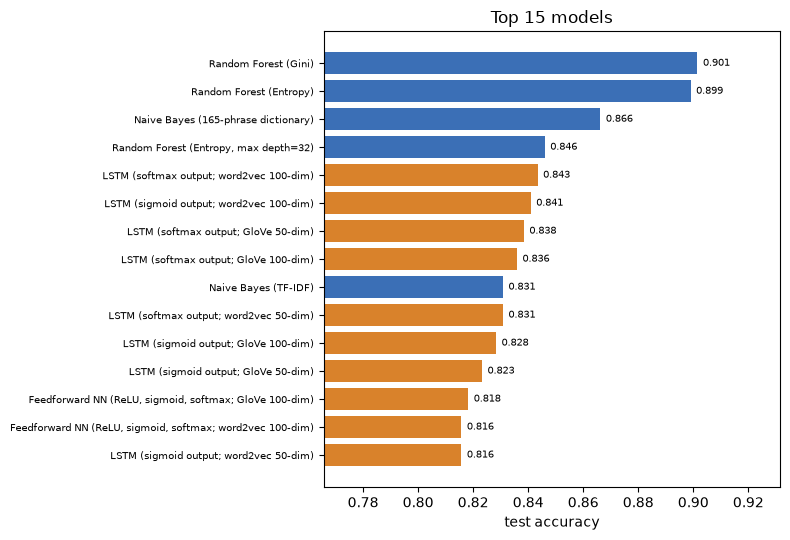

In [4]:
cols = ['model', 'family', 'features', 'accuracy', 'macro_f1', 'f1_class0', 'f1_class1', 'f1_class2']
tbl = three.sort_values(['accuracy', 'macro_f1'], ascending=False)[cols].reset_index(drop=True)
tbl.insert(0, 'rank', tbl.index + 1)
display(tbl)
tbl.to_csv(RES_DIR / 'final_comparison.csv', index=False)

short = tbl.head(15).iloc[::-1]
colors = {'TF-IDF': '#3b6fb6', 'Neural net': '#d9822b'}
plt.figure(figsize=(8, 5.5))
plt.barh(short.model, short.accuracy, color=[colors[f] for f in short.family])
plt.xlabel('test accuracy'); plt.title('Top 15 models'); plt.xlim(max(0, short.accuracy.min() - 0.05), min(1, short.accuracy.max() + 0.03))
for i, v in enumerate(short.accuracy): plt.text(v + 0.002, i, f'{v:.3f}', va='center', fontsize=7)
plt.yticks(fontsize=7); plt.tight_layout(); plt.savefig(RES_DIR / 'figures' / 'accuracy_comparison.png', dpi=150); plt.show()

In [5]:
def feat_group(f):
    return 'TF-IDF' if 'TF-IDF' in f or 'dictionary' in f else ('word2vec (our chat data)' if 'word2vec' in f else 'GloVe (news text)')
three['feature_group'] = three.features.map(feat_group)
grp = three.groupby('feature_group').agg(models=('model', 'count'), best_accuracy=('accuracy', 'max'), mean_accuracy=('accuracy', 'mean'),
                                         best_macro_f1=('macro_f1', 'max'), mean_macro_f1=('macro_f1', 'mean')).round(4)
display(grp)
cov_file = EMB_DIR / 'coverage.json'
if cov_file.exists():
    print('How many chat words does each embedding know?'); display(pd.DataFrame(json.load(open(cov_file))).T)

,models,best_accuracy,mean_accuracy,best_macro_f1,mean_macro_f1
feature_group,,,,,
GloVe (news text),10,0.8384,0.8142,0.7123,0.6804
TF-IDF,9,0.9015,0.7753,0.8247,0.6488
word2vec (our chat data),10,0.8434,0.8149,0.7226,0.6688


How many chat words does each embedding know?


,vocab_words_found_pct,word_occurrences_found_pct
w2v_50,99.6,99.9
w2v_100,99.6,99.9
glove_50,93.7,97.8
glove_100,93.7,97.8


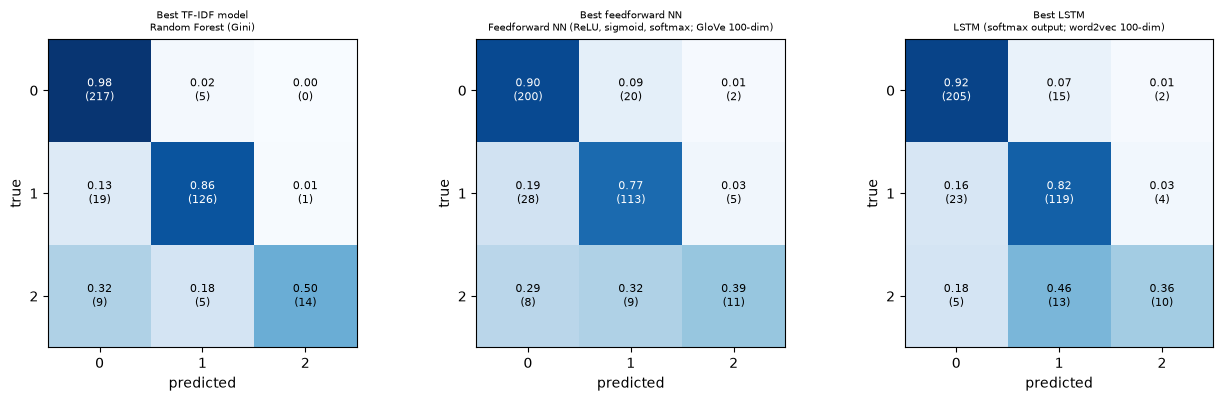

In [6]:
def best_of(mask):
    return three[mask].sort_values(['accuracy', 'macro_f1'], ascending=False).iloc[0].model

picks = {'Best TF-IDF model': best_of(three.family == 'TF-IDF'),
         'Best feedforward NN': best_of(three.model.str.startswith('Feedforward')),
         'Best LSTM': best_of(three.model.str.startswith('LSTM'))}

import re
def load_pred(name):
    return pd.read_csv(RES_DIR / 'preds' / (re.sub(r'[^a-z0-9]+', '_', name.lower()).strip('_') + '.csv'))

fig, axes = plt.subplots(1, 3, figsize=(13, 4))
for ax, (title, name) in zip(axes, picks.items()):
    p = load_pred(name)
    cm = confusion_matrix(p.y_true, p.y_pred, labels=[0, 1, 2]); cmn = cm / cm.sum(1, keepdims=True)
    ax.imshow(cmn, cmap='Blues', vmin=0, vmax=1)
    for i in range(3):
        for j in range(3): ax.text(j, i, f'{cmn[i, j]:.2f}\n({cm[i, j]})', ha='center', va='center', fontsize=8, color='white' if cmn[i, j] > 0.5 else 'black')
    ax.set_xticks(range(3)); ax.set_yticks(range(3)); ax.set_xticklabels(['0', '1', '2']); ax.set_yticklabels(['0', '1', '2'])
    ax.set_xlabel('predicted'); ax.set_ylabel('true'); ax.set_title(title + '\n' + name, fontsize=7)
plt.tight_layout(); plt.savefig(RES_DIR / 'figures' / 'confusion_matrices.png', dpi=150); plt.show()

In [7]:
def acc(name_part, df=three):
    sub = df[df.model.str.contains(name_part, regex=False)]
    return float(sub.accuracy.max()) if len(sub) else np.nan
paper = [('Binary SVM (linear)', 0.9565, acc('Binary SVM (linear', binary)),
         ('Binary SVM (rbf)', 0.9635, acc('Binary SVM (rbf', binary)),
         ('Naive Bayes (TF-IDF)', 0.9506, acc('Naive Bayes (TF-IDF)')),
         ('KNN K=1', 0.9853, acc('KNN (K=1)')), ('KNN K=2', 0.9711, acc('KNN (K=2)')), ('KNN K=3', 0.9683, acc('KNN (K=3)')), ('KNN K=6', 0.8424, acc('KNN (K=6)')),
         ('Random Forest (Gini)', 0.9912, acc('Random Forest (Gini)')), ('Random Forest (Entropy)', 0.9910, acc('Random Forest (Entropy)')),
         ('Best feedforward NN', 0.9572, acc('Feedforward')), ('Best LSTM', 0.9586, acc('LSTM'))]
cmp_tbl = pd.DataFrame(paper, columns=['model', 'paper accuracy', 'our accuracy']).round(4)
cmp_tbl['difference'] = (cmp_tbl['our accuracy'] - cmp_tbl['paper accuracy']).round(4)
display(cmp_tbl); cmp_tbl.to_csv(RES_DIR / 'paper_vs_ours.csv', index=False)


,model,paper accuracy,our accuracy,difference
0,Binary SVM (linear),0.9565,0.9217,-0.0348
1,Binary SVM (rbf),0.9635,0.8914,-0.0721
2,Naive Bayes (TF-IDF),0.9506,0.8308,-0.1198
3,KNN K=1,0.9853,0.6894,-0.2959
4,KNN K=2,0.9711,0.6667,-0.3044
5,KNN K=3,0.9683,0.6566,-0.3117
6,KNN K=6,0.8424,0.6212,-0.2212
7,Random Forest (Gini),0.9912,0.9015,-0.0897
8,Random Forest (Entropy),0.9910,0.8990,-0.0920
9,Best feedforward NN,0.9572,0.8182,-0.1390


In [8]:
best_name = tbl.iloc[0].model
p = load_pred(best_name).merge(test[['id', 'text']], on='id')
err = p[p.y_true != p.y_pred].copy()
err['true'] = err.y_true.map(dict(enumerate(CLASS_NAMES))); err['predicted'] = err.y_pred.map(dict(enumerate(CLASS_NAMES)))
err[['id', 'text', 'true', 'predicted']].to_csv(RES_DIR / 'error_analysis.csv', index=False)
print(f'Best model overall: {best_name}  ({len(err)} errors out of {len(p)} test messages)')
display(err[['text', 'true', 'predicted']].head(20))
print(pd.crosstab(err.true, err.predicted))


Best model overall: Random Forest (Gini)  (39 errors out of 396 test messages)


,text,true,predicted
7,TINKER how much did you pay to gaben to play a...,derogatory,neutral/positive
12,son of a whore cm,derogatory,neutral/positive
13,OMG Repor>T THIS FAGOOT PLS,derogatory,neutral/positive
15,faggot ass bs,derogatory,neutral/positive
20,now i will not go with u,negative attitude,neutral/positive
33,get out of my base bitches,negative attitude,neutral/positive
38,lets get these suckers janna,negative attitude,neutral/positive
45,little faggot,derogatory,neutral/positive
81,good boy kids,negative attitude,neutral/positive
90,yeah repot me xD,negative attitude,neutral/positive


predicted          derogatory  negative attitude  neutral/positive
true                                                              
derogatory                  0                  5                 9
negative attitude           1                  0                19
neutral/positive            0                  5                 0
